# Radiotherapy Beamlet Planning with Constrained Optimization

A small computational study of how optimization can balance target coverage against dose limits for nearby organs at risk (OARs).

This notebook uses a **simplified, illustrative two-beamlet model**. Dose units and coefficients are synthetic and are not suitable for clinical planning or treatment decisions.

## Questions explored
- What makes the quadratic objective convex?
- How do linear dose constraints define a feasible region?
- How do quadratic and linear objectives lead to different optimal plans?
- How can numerical solutions be checked and visualized?

**Tools:** Python, NumPy, SciPy and Matplotlib.

## 1. Model and assumptions

Let \(x_1\) and \(x_2\) be non-negative beamlet intensities. The dose delivered to each region is a linear combination of these intensities.

| Region | Beamlet 1 coefficient | Beamlet 2 coefficient | Requirement |
|---|---:|---:|---:|
| Target | 1.2 | 0.8 | at least 10 |
| OAR 1 | 0.3 | 0.6 | at most 6 |
| OAR 2 | 0.8 | 0.2 | at most 7 |

The first objective penalizes larger intensities using a weighted quadratic cost:

\[
f(x_1,x_2)=x_1^2+1.5x_2^2.
\]

The constraints are linear, so their intersection with the non-negative quadrant forms a convex feasible region.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, linprog

# Rows represent target, OAR 1 and OAR 2; columns represent beamlets.
dose_matrix = np.array([
    [1.2, 0.8],
    [0.3, 0.6],
    [0.8, 0.2]
])
lower_target = 10.0
upper_oar1 = 6.0
upper_oar2 = 7.0

def delivered_doses(x):
    """Return target, OAR 1 and OAR 2 doses for a pair of intensities."""
    return dose_matrix @ np.asarray(x, dtype=float)

def quadratic_cost(x):
    """Weighted quadratic penalty on beamlet intensities."""
    x1, x2 = x
    return x1**2 + 1.5*x2**2

# Constraints for scipy.optimize.minimize use a non-negative value when satisfied.
constraints = [
    {'type': 'ineq', 'fun': lambda x: delivered_doses(x)[0] - lower_target},
    {'type': 'ineq', 'fun': lambda x: upper_oar1 - delivered_doses(x)[1]},
    {'type': 'ineq', 'fun': lambda x: upper_oar2 - delivered_doses(x)[2]}
]
bounds = [(0, None), (0, None)]

result_quad = minimize(
    quadratic_cost, x0=np.array([6.0, 3.0]),
    method='SLSQP', bounds=bounds, constraints=constraints,
    options={'ftol': 1e-12, 'maxiter': 500}
)
if not result_quad.success:
    raise RuntimeError(result_quad.message)

x_quad = result_quad.x
f_quad = result_quad.fun
print("Quadratic optimum:", x_quad)
print("Quadratic cost:", f_quad)
print("Delivered doses [target, OAR1, OAR2]:", delivered_doses(x_quad))

Quadratic optimum: [6.42857143 2.85714285]
Quadratic cost: 53.571428571427234
Delivered doses [target, OAR1, OAR2]: [10.          3.64285714  5.71428572]


## 2. Why the quadratic objective is convex

The gradient and Hessian are

\[
\nabla f = \begin{pmatrix}2x_1\\3x_2\end{pmatrix},
\qquad
\nabla^2 f = \begin{pmatrix}2&0\\0&3\end{pmatrix}.
\]

Both eigenvalues of the Hessian are positive. Therefore the Hessian is positive definite and the objective is strictly convex. Each linear inequality defines a half-plane, which is convex; the intersection of these half-planes and the non-negative quadrant is also convex.

A strictly convex objective over a nonempty convex feasible set has at most one global minimizer.

## 3. Visualize the feasible region and quadratic objective

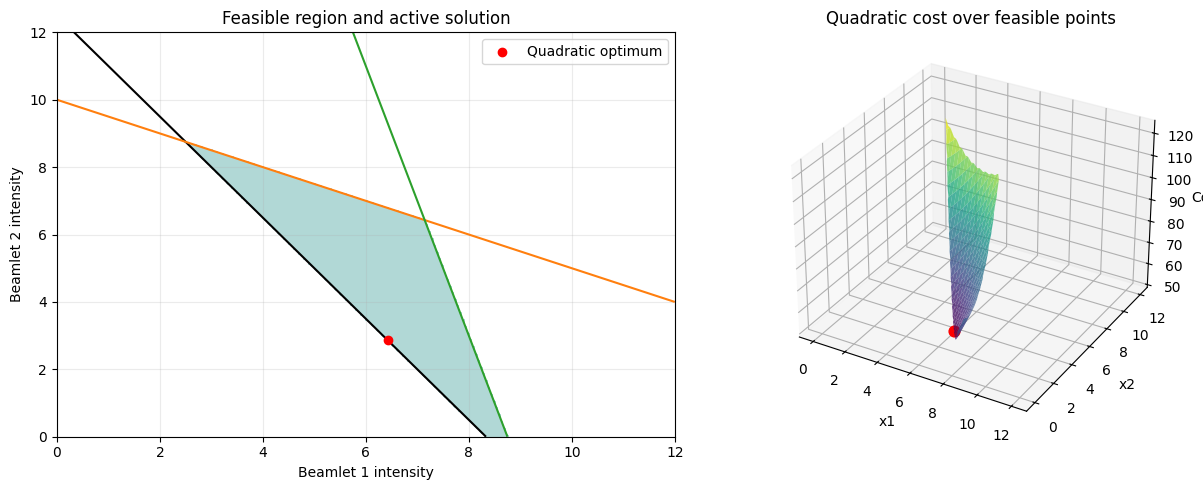

In [2]:
# Build a grid of candidate intensities and mark points satisfying every dose limit.
x1_values = np.linspace(0, 12, 240)
x2_values = np.linspace(0, 12, 240)
X1, X2 = np.meshgrid(x1_values, x2_values)
target_dose = 1.2*X1 + 0.8*X2
oar1_dose = 0.3*X1 + 0.6*X2
oar2_dose = 0.8*X1 + 0.2*X2
feasible = ((target_dose >= lower_target) &
            (oar1_dose <= upper_oar1) &
            (oar2_dose <= upper_oar2))

fig = plt.figure(figsize=(13, 5))
ax1 = fig.add_subplot(1, 2, 1)
ax1.contourf(X1, X2, feasible.astype(int), levels=[0.5, 1.5], alpha=0.35)
ax1.contour(X1, X2, target_dose, levels=[lower_target], colors='black')
ax1.contour(X1, X2, oar1_dose, levels=[upper_oar1], colors='tab:orange')
ax1.contour(X1, X2, oar2_dose, levels=[upper_oar2], colors='tab:green')
ax1.scatter(*x_quad, color='red', label='Quadratic optimum', zorder=5)
ax1.set(xlabel='Beamlet 1 intensity', ylabel='Beamlet 2 intensity',
        title='Feasible region and active solution')
ax1.legend()
ax1.grid(alpha=0.25)

Z = X1**2 + 1.5*X2**2
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.plot_surface(X1, X2, np.where(feasible, Z, np.nan),
                 cmap='viridis', alpha=0.8, linewidth=0)
ax2.scatter(x_quad[0], x_quad[1], f_quad, color='red', s=60)
ax2.set(xlabel='x1', ylabel='x2', zlabel='Cost',
        title='Quadratic cost over feasible points')
plt.tight_layout()
plt.show()

## 4. Check feasibility and interpret the solution

A numerical optimizer should not be trusted only because it returns a result. We also check the original dose constraints and the non-negativity bounds directly.

In [3]:
dose_quad = delivered_doses(x_quad)
checks = {
    "Target dose >= 10": dose_quad[0] >= lower_target - 1e-7,
    "OAR 1 dose <= 6": dose_quad[1] <= upper_oar1 + 1e-7,
    "OAR 2 dose <= 7": dose_quad[2] <= upper_oar2 + 1e-7,
    "Intensities non-negative": np.all(x_quad >= -1e-7)
}
for description, passed in checks.items():
    print(f"{description}: {'PASS' if passed else 'FAIL'}")
assert all(checks.values())

Target dose >= 10: PASS
OAR 1 dose <= 6: PASS
OAR 2 dose <= 7: PASS
Intensities non-negative: PASS


## 5. Compare with a linear objective

Now minimize \(g(x_1,x_2)=x_1+x_2\) under the same constraints. This is a linear program. With a finite optimum, a linear objective over a polygonal feasible region has at least one optimal vertex.

`linprog` expects inequalities in the form \(A_{ub}x\le b_{ub}\). The target minimum is therefore multiplied by -1.

In [4]:
# Convert all dose requirements to A_ub @ x <= b_ub.
A_ub = np.array([
    [-1.2, -0.8],  # target dose >= 10
    [0.3, 0.6],    # OAR 1 dose <= 6
    [0.8, 0.2]     # OAR 2 dose <= 7
])
b_ub = np.array([-10.0, 6.0, 7.0])

result_linear = linprog(
    c=[1.0, 1.0], A_ub=A_ub, b_ub=b_ub,
    bounds=[(0, None), (0, None)], method='highs'
)
if not result_linear.success:
    raise RuntimeError(result_linear.message)

x_linear = result_linear.x
f_linear = result_linear.fun
print("Linear optimum:", x_linear)
print("Linear cost:", f_linear)
print("Delivered doses [target, OAR1, OAR2]:", delivered_doses(x_linear))

Linear optimum: [8.33333333 0.        ]
Linear cost: 8.333333333333334
Delivered doses [target, OAR1, OAR2]: [10.          2.5         6.66666667]


Objective                 x1        x2      Target     OAR 1     OAR 2
Quadratic              6.429     2.857      10.000     3.643     5.714
Linear                 8.333     0.000      10.000     2.500     6.667


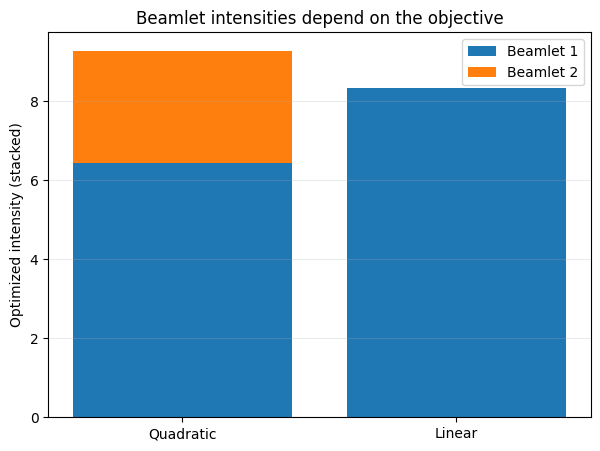

In [5]:
# Compare the two optimal plans in a compact table-like printout.
print(f"{'Objective':<18}{'x1':>10}{'x2':>10}{'Target':>12}{'OAR 1':>10}{'OAR 2':>10}")
for name, x in [('Quadratic', x_quad), ('Linear', x_linear)]:
    d = delivered_doses(x)
    print(f"{name:<18}{x[0]:>10.3f}{x[1]:>10.3f}{d[0]:>12.3f}{d[1]:>10.3f}{d[2]:>10.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(['Quadratic', 'Linear'], [x_quad[0], x_linear[0]], label='Beamlet 1')
ax.bar(['Quadratic', 'Linear'], [x_quad[1], x_linear[1]],
       bottom=[x_quad[0], x_linear[0]], label='Beamlet 2')
ax.set_ylabel('Optimized intensity (stacked)')
ax.set_title('Beamlet intensities depend on the objective')
ax.legend()
ax.grid(axis='y', alpha=0.25)
plt.show()

## 6. What the algorithms are doing

**SLSQP (quadratic problem):** starts from an initial guess, builds local approximations of the constrained problem, and iteratively updates the variables while respecting the bounds and dose constraints. It stops when the objective and constraint changes meet its convergence tolerances.

**HiGHS linear programming solver:** solves the linear program using a modern LP algorithm (the `highs` method selects the solver automatically). Linear programming optima occur at vertices when a finite optimum exists.

The two objective functions are different, so their numerical cost values should not be compared directly. The meaningful comparison is how each objective selects a different feasible intensity combination.

## 7. Limitations

This is a deliberately small mathematical example with two beamlets, three regions, fixed dose coefficients and arbitrary units. Real radiotherapy planning involves three-dimensional anatomy, many beamlets, dose-volume objectives, uncertainty, machine constraints, and specialist clinical validation. This notebook is for learning optimization concepts only; it is not a treatment-planning tool.

## 8. Summary

- The quadratic objective is strictly convex because its Hessian is positive definite.
- Linear dose constraints produce a convex feasible region.
- The quadratic and linear objectives can select different optimal plans.
- Always verify the delivered doses and variable bounds after numerical optimization.